<a href="https://colab.research.google.com/github/sugarfreecat/scrum/blob/main/analise_vendas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dados limpos:
   pedido    categoria  valor     status
0     101  Eletrônicos  250.0       Pago
1     102   Acessórios   80.0       Pago
2     103  Eletrônicos  320.0   Pendente
4     105   Acessórios   80.0       Pago
5     106         Casa  190.0  Cancelado

Resumo de vendas pagas por categoria:
             count    sum   mean
categoria                       
Acessórios       2  160.0   80.0
Eletrônicos      1  250.0  250.0


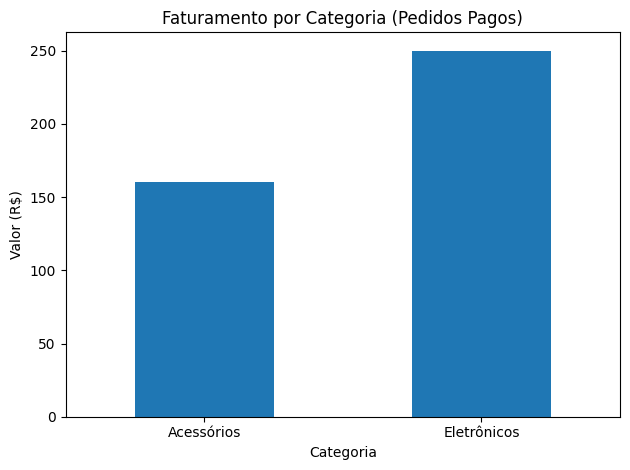

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. LIMPEZA DE DADOS
# Exemplo com uma mini base de vendas para testar o fluxo da equipe
dados = {
    "pedido": [101, 102, 103, 104, 105, 106],
    "categoria": ["Eletrônicos", "Acessórios", "eletrônicos", None, "Acessórios", "Casa"],
    "valor": [250.0, 80.0, 320.0, 150.0, 80.0, 190.0],
    "status": ["Pago", "Pago", "Pendente", "Pago", "Pago", "Cancelado"]
}

df = pd.DataFrame(dados)

# Padronização simples e remoção de linhas sem categoria
df["categoria"] = df["categoria"].str.strip().str.capitalize()
df_limpo = df.dropna(subset=["categoria"]).drop_duplicates(subset=["pedido"]).copy()

print("Dados limpos:")
print(df_limpo)

# 2. ANÁLISE EXPLORATÓRIA
vendas_validas = df_limpo[df_limpo["status"] == "Pago"]
resumo_categoria = vendas_validas.groupby("categoria")["valor"].agg(["count", "sum", "mean"])

print("\nResumo de vendas pagas por categoria:")
print(resumo_categoria)

# 3. VISUALIZAÇÃO
resumo_categoria["sum"].plot(kind="bar", title="Faturamento por Categoria (Pedidos Pagos)")
plt.ylabel("Valor (R$)")
plt.xlabel("Categoria")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()